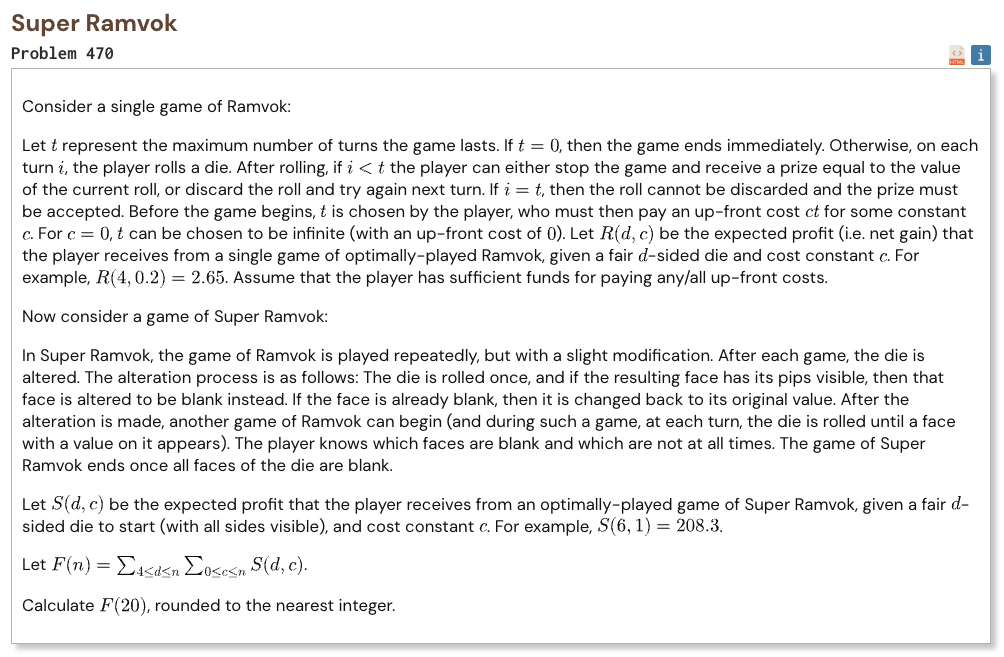

## Initial approach

- solve the best Ramvok profit for every possible set of visible die faces
- for each state, try the useful turn limits and keep the best profit
- group die states by how many visible faces they contain
- calculate how often Super Ramvok is expected to visit each group before all faces become blank
- combine those visit counts with the average Ramvok profit of each group
- repeat this for dice from 4 to 20 sides and round the final total

In [1]:
import math

N = 20

def ramvok_profits(mask, d):
    values = []
    total = 0

    for i in range(d):
        if mask & (1 << i):
            values.append(i + 1)
            total += i + 1

    k = len(values)
    maximum = values[-1]

    best = [0.0] * (N + 1)
    best[0] = float(maximum)

    expected = 0.0

    for turns in range(1, maximum + 1):
        expected = sum(max(value, expected) for value in values) / k

        for cost in range(1, N + 1):
            profit = expected - cost * turns

            if profit > best[cost]:
                best[cost] = profit

    return best

def solve_linear(matrix, vector):
    n = len(vector)

    for col in range(n):
        pivot = max(
            range(col, n),
            key=lambda row: abs(matrix[row][col])
        )

        matrix[col], matrix[pivot] = matrix[pivot], matrix[col]
        vector[col], vector[pivot] = vector[pivot], vector[col]

        scale = matrix[col][col]

        for j in range(col, n):
            matrix[col][j] /= scale

        vector[col] /= scale

        for row in range(n):
            if row == col:
                continue

            factor = matrix[row][col]

            if factor == 0:
                continue

            for j in range(col, n):
                matrix[row][j] -= factor * matrix[col][j]

            vector[row] -= factor * vector[col]

    return vector

def expected_visits(d):
    matrix = [
        [0.0] * d
        for _ in range(d)
    ]

    vector = [0.0] * d
    vector[d - 1] = 1.0

    for k in range(1, d + 1):
        matrix[k - 1][k - 1] = 1.0

        if k < d:
            matrix[k - 1][k] -= (d - k) / d

        if k > 1:
            matrix[k - 1][k - 2] -= k / d

    return [0.0] + solve_linear(matrix, vector)

def super_ramvok(d):
    visits = expected_visits(d)

    sums = [
        [0.0] * (N + 1)
        for _ in range(d + 1)
    ]

    for mask in range(1, 1 << d):
        k = mask.bit_count()
        profits = ramvok_profits(mask, d)

        for cost in range(N + 1):
            sums[k][cost] += profits[cost]

    result = [0.0] * (N + 1)

    for cost in range(N + 1):
        for k in range(1, d + 1):
            average = sums[k][cost] / math.comb(d, k)
            result[cost] += visits[k] * average

    return result

In [2]:
%%time

total = 0.0

for d in range(4, N + 1):
    values = super_ramvok(d)
    total += sum(values)

result = round(total)

print("Result:", result)

Result: 9933
CPU times: user 1min 10s, sys: 417 ms, total: 1min 10s
Wall time: 1min 11s
